In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score

uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Saving placement_predict_50k Dataset.csv to placement_predict_50k Dataset.csv
Dataset loaded successfully!
Shape: (50000, 32)
Columns: ['StudentID', 'Gender', 'City', 'CollegeTier', 'Stream', 'Specialisation', 'Hostel', 'HistoryOfBacklogs', 'SGPA_Sem1', 'SGPA_Sem2', 'SGPA_Sem3', 'SGPA_Sem4', 'SGPA_Sem5', 'SGPA_Sem6', 'SGPA_Sem7', 'SGPA_Sem8', 'CGPA', 'AttendancePercent', 'Internships', 'Projects', 'Workshops', 'Certifications', 'Publications', 'AptitudeTestScore', 'SoftSkillsRating', 'CodingTestScore', 'MockInterviewScore', 'ExtraCurricular', 'CGPA_Tier', 'PlacementStatus', 'IsAnomaly', 'Salary Package']


,StudentID,Gender,City,CollegeTier,Stream,Specialisation,Hostel,HistoryOfBacklogs,SGPA_Sem1,SGPA_Sem2,...,Publications,AptitudeTestScore,SoftSkillsRating,CodingTestScore,MockInterviewScore,ExtraCurricular,CGPA_Tier,PlacementStatus,IsAnomaly,Salary Package
0,1,Male,Ahmedabad,Tier2,ECE,Networking,No,No,6.02,6.54,...,0,66.7,2.2,49.4,47.8,0,Low,0,0,0.00
1,2,Female,Mumbai,Tier2,ECE,DataScience,Yes,Yes,5.84,5.12,...,0,48.2,2.4,26.7,25.8,0,Low,0,0,0.00
2,3,Male,Kolkata,Tier2,IT,DataScience,Yes,No,4.91,5.29,...,0,73.8,2.8,67.7,41.5,0,Low,1,0,3.89
3,4,Male,Jaipur,Tier1,CS,AI,No,No,7.67,8.03,...,0,69.8,2.7,66.9,48.0,0,Mid,1,0,8.37
4,5,Male,Pune,Tier2,IT,DataScience,Yes,No,8.14,8.97,...,1,73.1,2.1,71.7,61.7,1,High,1,0,18.99


In [ ]:

X = df.drop(columns=["PlacementStatus", "CGPA_Tier"])
y = df["PlacementStatus"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)


Training shape: (40000, 52)
Validation shape: (10000, 52)


In [ ]:

def rf_vs_single_tree(X_train, y_train, X_val, y_val, n_estimators_list):
    results = []

    for n in n_estimators_list:
        rf = RandomForestClassifier(
            n_estimators=n,
            max_features="sqrt",
            bootstrap=True,
            oob_score=True,
            random_state=42,
            n_jobs=-1
        )

        dt = DecisionTreeClassifier(random_state=42)

        rf.fit(X_train, y_train)
        dt.fit(X_train, y_train)

        rf_val_acc = accuracy_score(y_val, rf.predict(X_val))
        dt_val_acc = accuracy_score(y_val, dt.predict(X_val))

        # OOB score is accuracy on out-of-bag training samples
        oob_acc = rf.oob_score_

        results.append({
            "n_estimators": n,
            "RF_val_acc": rf_val_acc,
            "DT_val_acc": dt_val_acc,
            "OOB_acc": oob_acc
        })

    report = pd.DataFrame(results)

    # Plot 1: Validation accuracy comparison
    plt.figure(figsize=(9, 5))
    plt.plot(report["n_estimators"], report["RF_val_acc"],
             marker="o", label="Random Forest")
    plt.plot(report["n_estimators"], report["DT_val_acc"],
             marker="s", label="Single Decision Tree")
    plt.xlabel("Number of Trees")
    plt.ylabel("Validation Accuracy")
    plt.title("Random Forest vs Single Decision Tree")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Plot 2: OOB accuracy / convergence
    plt.figure(figsize=(9, 5))
    plt.plot(report["n_estimators"], report["OOB_acc"], marker="o")
    plt.xlabel("Number of Trees")
    plt.ylabel("OOB Accuracy")
    plt.title("OOB Accuracy and Convergence")
    plt.grid(True)
    plt.show()

    # Plot 3: Validation accuracy difference
    plt.figure(figsize=(9, 5))
    plt.plot(
        report["n_estimators"],
        report["RF_val_acc"] - report["DT_val_acc"],
        marker="o"
    )
    plt.axhline(0, linewidth=1)
    plt.xlabel("Number of Trees")
    plt.ylabel("RF Accuracy - DT Accuracy")
    plt.title("Improvement from Random Forest")
    plt.grid(True)
    plt.show()

    print("Best Random Forest result:")
    print(report.loc[report["RF_val_acc"].idxmax()])

    return report


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


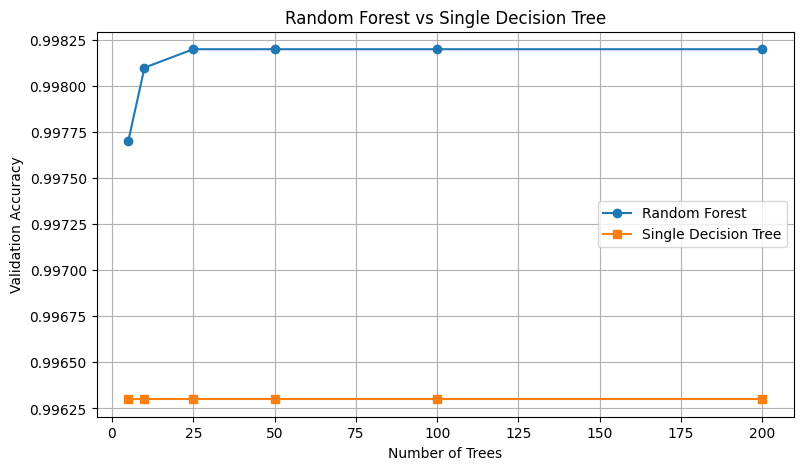

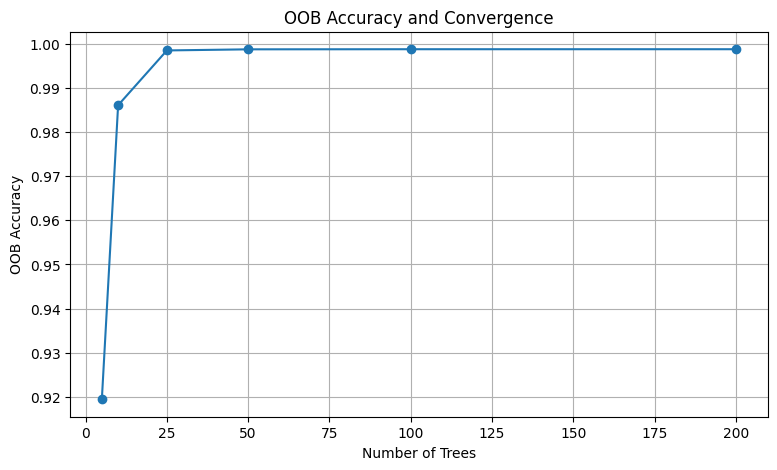

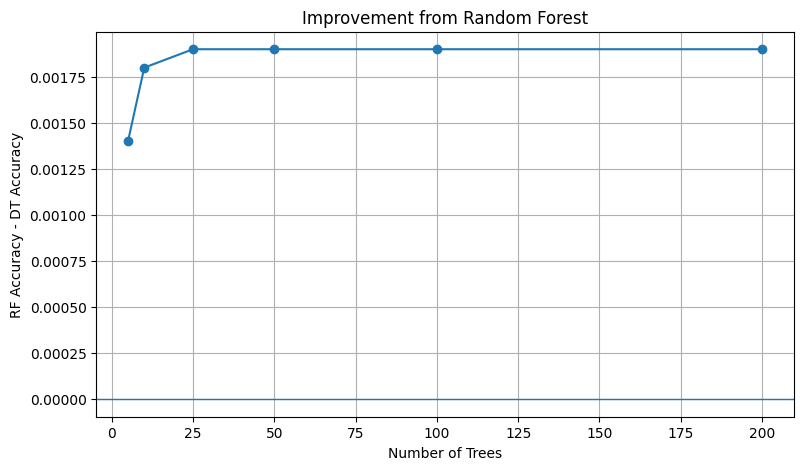

Best Random Forest result:
n_estimators    25.00000
RF_val_acc       0.99820
DT_val_acc       0.99630
OOB_acc          0.99845
Name: 2, dtype: float64


,n_estimators,RF_val_acc,DT_val_acc,OOB_acc
0,5,0.9977,0.9963,0.9195
1,10,0.9981,0.9963,0.9860
2,25,0.9982,0.9963,0.9984
3,50,0.9982,0.9963,0.9987
4,100,0.9982,0.9963,0.9987
5,200,0.9982,0.9963,0.9987


In [ ]:

n_estimators_list = [5, 10, 25, 50, 100, 200]

rf_results = rf_vs_single_tree(
    X_train_processed,
    y_train,
    X_val_processed,
    y_val,
    n_estimators_list
)

display(rf_results.round(4))


,max_features,Validation Accuracy,OOB Accuracy
0,sqrt,0.9982,0.9987
1,log2,0.9982,0.9987
2,None,0.9982,0.9987


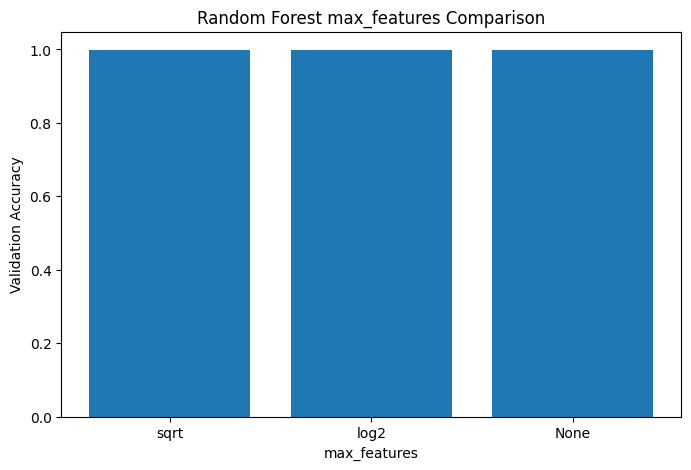

In [ ]:

feature_options = ["sqrt", "log2", None]
feature_results = []

for option in feature_options:
    model = RandomForestClassifier(
        n_estimators=100,
        max_features=option,
        oob_score=True,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_processed, y_train)

    feature_results.append({
        "max_features": str(option),
        "Validation Accuracy": accuracy_score(
            y_val, model.predict(X_val_processed)
        ),
        "OOB Accuracy": model.oob_score_
    })

feature_df = pd.DataFrame(feature_results)
display(feature_df.round(4))

plt.figure(figsize=(8, 5))
plt.bar(feature_df["max_features"], feature_df["Validation Accuracy"])
plt.xlabel("max_features")
plt.ylabel("Validation Accuracy")
plt.title("Random Forest max_features Comparison")
plt.show()


In [ ]:

from sklearn.base import clone

rng = np.random.default_rng(42)
n_samples = X_train_processed.shape[0]
manual_predictions = []

for i in range(100):
    indices = rng.choice(n_samples, size=n_samples, replace=True)

    X_boot = X_train_processed[indices]
    y_boot = y_train.iloc[indices] if hasattr(y_train, "iloc") else y_train[indices]

    tree = DecisionTreeClassifier(random_state=i)
    tree.fit(X_boot, y_boot)

    manual_predictions.append(tree.predict(X_val_processed))

manual_predictions = np.array(manual_predictions)

# Majority vote across bootstrap trees
majority_predictions = []
for column in manual_predictions.T:
    values, counts = np.unique(column, return_counts=True)
    majority_predictions.append(values[np.argmax(counts)])

manual_bagging_acc = accuracy_score(y_val, majority_predictions)
print("Manual Bootstrap Bagging Validation Accuracy:",
      round(manual_bagging_acc, 4))


Manual Bootstrap Bagging Validation Accuracy: 0.9982
